# Download, preparação e inspeção de dados (NIDDK - Diabetes Dataset)

<mark>Este notebook é didático e não deve ser utilizado para realizar diagnósticos</mark>

## Sobre o conjunto de dados

Este conjunto de dados tem como origem o [National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK)](https://www.niddk.nih.gov/) para estudos relacionados ao diabetes. Não assumimos que os registros sejam representativos de uma população clínica.

Os dados estão disponíveis no repositório [MicrosoftLearning/AI-900-AIFundamentals](https://github.com/MicrosoftLearning/AI-900-AIFundamentals/blob/main/data/ml/diabetes.csv), que é registrado como o canal de download.

## Bibliotecas e caminhos

As pastas são criadas automaticamente. O Parquet e os arquivos de origem ficam em `data/`, ignorada pelo Git.

### Bibliotecas

In [14]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import io
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")


def find_project_root():
    """Procura o diretório raiz do projeto."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml" / "pyproject.toml").is_file() and (
            candidate / "README.md"
        ).is_file():
            return candidate
    raise FileNotFoundError("Abra o notebook dentro deste repositório.")

### Variáveis

In [15]:
PROJECT_ROOT = find_project_root()

DATASET_URL = "https://raw.githubusercontent.com/MicrosoftLearning/AI-900-AIFundamentals/main/data/ml/diabetes.csv"
SOURCE_PAGE = "https://www.niddk.nih.gov/"
DISTRIBUTION_PAGE = "https://github.com/MicrosoftLearning/AI-900-AIFundamentals/blob/main/data/ml/diabetes.csv"
DATA_DIR = PROJECT_ROOT / "data" / "niddk-diabetes"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "diabetes.csv"
PARQUET_PATH = DATA_DIR / "diabetes.parquet"
METADATA_PATH = DATA_DIR / "source.json"

COLUMN_TRANSLATIONS = {
    "PatientID": "id_paciente",
    "Pregnancies": "gestacoes",
    "PlasmaGlucose": "glicose_plasmatica",
    "DiastolicBloodPressure": "pressao_arterial_diastolica",
    "TricepsThickness": "espessura_triceps",
    "SerumInsulin": "insulina_serica",
    "BMI": "imc",
    "DiabetesPedigree": "indice_hereditariedade_diabetes",
    "Age": "idade",
    "Diabetic": "classe",
}

RAW_TARGET = "Diabetic"
TARGET = COLUMN_TRANSLATIONS[RAW_TARGET]
EXPECTED_COLUMNS = [
    "PatientID",
    "Pregnancies",
    "PlasmaGlucose",
    "DiastolicBloodPressure",
    "TricepsThickness",
    "SerumInsulin",
    "BMI",
    "DiabetesPedigree",
    "Age",
    "Diabetic",
]
FORCE_DOWNLOAD = False

print(f"Pasta de dados: {DATA_DIR.relative_to(PROJECT_ROOT).as_posix()}")

Pasta de dados: data/niddk-diabetes


## Download e leitura

O arquivo existente é reutilizado. Para baixar novamente, altere `FORCE_DOWNLOAD`. O conteúdo recebido é validado antes de substituir o CSV local; uma falha de rede pode ser corrigida executando a célula novamente.

In [16]:
if FORCE_DOWNLOAD or not CSV_PATH.is_file():

    response = requests.get(DATASET_URL, timeout=(15, 60))
    response.raise_for_status()

    csv_bytes = response.content
    candidate = pd.read_csv(io.BytesIO(csv_bytes))

    if candidate.empty or list(candidate.columns) != EXPECTED_COLUMNS:
        raise ValueError(
            "O arquivo recebido está vazio ou seu esquema mudou. Confira a fonte."
        )

    temporary_path = CSV_PATH.with_suffix(".csv.part")
    temporary_path.write_bytes(csv_bytes)
    temporary_path.replace(CSV_PATH)

    metadata = {
        "source_page": SOURCE_PAGE,
        "distribution_page": DISTRIBUTION_PAGE,
        "download_url": DATASET_URL,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "csv_sha256": hashlib.sha256(csv_bytes).hexdigest(),
    }

    METADATA_PATH.write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("Download concluído.")
else:
    print("Usando o CSV já disponível.")

data = pd.read_csv(CSV_PATH)

if data.empty or list(data.columns) != EXPECTED_COLUMNS:
    raise ValueError("CSV local vazio ou com colunas inesperadas. Confira o arquivo.")

if RAW_TARGET not in data:
    raise ValueError("Coluna alvo ausente.")

expected_classes = {0, 1}

if data[RAW_TARGET].isna().any() or set(data[RAW_TARGET].unique()) != expected_classes:
    raise ValueError("A coluna alvo contém valores ausentes ou classes inesperadas.")

print("Visualização do conjunto de dados original:")
display(data.head())

Usando o CSV já disponível.
Visualização do conjunto de dados original:


,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


## Preparação e salvamento em Parquet

Abaixo, o conjunto de dados original é transformado: as colunas são traduzidas para PT-BR e normalizadas em `lowercase` com `_` como separador. A variável alvo já está codificada como `0`/`1` e é armazenada como `int8`. A prévia permite comparar o resultado com o CSV original exibido na seção anterior. Não removemos duplicatas, imputamos ausências ou normalizamos atributos. Essas decisões ficam para os experimentos posteriores.

In [17]:
data = data.rename(columns=COLUMN_TRANSLATIONS)
data[TARGET] = data[TARGET].astype("int8")

print("Visualização do conjunto de dados preparado:")
display(data.head())

temporary_parquet = PARQUET_PATH.with_suffix(".parquet.part")
data.to_parquet(temporary_parquet, engine="pyarrow", index=False)
restored = pd.read_parquet(temporary_parquet, engine="pyarrow")
pd.testing.assert_frame_equal(data, restored)
temporary_parquet.replace(PARQUET_PATH)

print(f"Parquet salvo e conferido: {PARQUET_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"{len(data):,} registros; {len(data.columns)} colunas.")

Visualização do conjunto de dados preparado:


,id_paciente,gestacoes,glicose_plasmatica,pressao_arterial_diastolica,espessura_triceps,insulina_serica,imc,indice_hereditariedade_diabetes,idade,classe
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


Parquet salvo e conferido: data/niddk-diabetes/diabetes.parquet
10,000 registros; 10 colunas.


## Estrutura e qualidade dos dados

Observe tipos, valores ausentes e duplicatas. Registros iguais não são automaticamente erros; avalie seu significado antes de removê-los.

In [18]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_paciente                      10000 non-null  int64  
 1   gestacoes                        10000 non-null  int64  
 2   glicose_plasmatica               10000 non-null  int64  
 3   pressao_arterial_diastolica      10000 non-null  int64  
 4   espessura_triceps                10000 non-null  int64  
 5   insulina_serica                  10000 non-null  int64  
 6   imc                              10000 non-null  float64
 7   indice_hereditariedade_diabetes  10000 non-null  float64
 8   idade                            10000 non-null  int64  
 9   classe                           10000 non-null  int8   
dtypes: float64(2), int64(7), int8(1)
memory usage: 713.0 KB


In [19]:
quality = pd.DataFrame({
    "tipo": data.dtypes.astype(str),
    "ausentes": data.isna().sum(),
    "ausentes_percentual": data.isna().mean().mul(100).round(2),
    "valores_distintos": data.nunique(dropna=False),
})

display(quality)

,tipo,ausentes,ausentes_percentual,valores_distintos
id_paciente,int64,0,0.0,9959
gestacoes,int64,0,0.0,15
glicose_plasmatica,int64,0,0.0,149
pressao_arterial_diastolica,int64,0,0.0,90
espessura_triceps,int64,0,0.0,66
insulina_serica,int64,0,0.0,620
imc,float64,0,0.0,10000
indice_hereditariedade_diabetes,float64,0,0.0,10000
idade,int64,0,0.0,56
classe,int8,0,0.0,2


In [20]:
print(f"Linhas inteiramente duplicadas: {data.duplicated().sum()}")

Linhas inteiramente duplicadas: 0


In [21]:
print(f"id_paciente duplicados: {data['id_paciente'].duplicated().sum()}")

id_paciente duplicados: 41


In [22]:
print(f"Duplicatas sem considerar id_paciente: {data.drop(columns='id_paciente').duplicated().sum()}")

Duplicatas sem considerar id_paciente: 0


In [23]:
display(data.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
id_paciente,10000.0,1.502122e+06,289286.764810,1.000038e+06,1.251672e+06,1.504394e+06,1.754608e+06,1.999997e+06
gestacoes,10000.0,3.255800e+00,3.405720,0.000000e+00,0.000000e+00,2.000000e+00,6.000000e+00,1.400000e+01
glicose_plasmatica,10000.0,1.078502e+02,31.920909,4.400000e+01,8.400000e+01,1.050000e+02,1.290000e+02,1.920000e+02
pressao_arterial_diastolica,10000.0,7.120750e+01,16.801478,2.400000e+01,5.800000e+01,7.200000e+01,8.500000e+01,1.170000e+02
espessura_triceps,10000.0,2.881760e+01,14.506480,7.000000e+00,1.500000e+01,3.100000e+01,4.100000e+01,9.200000e+01
insulina_serica,10000.0,1.392436e+02,133.777919,1.400000e+01,3.900000e+01,8.500000e+01,1.970000e+02,7.960000e+02
imc,10000.0,3.156702e+01,9.804366,1.820081e+01,2.124743e+01,3.192242e+01,3.932892e+01,5.603463e+01
indice_hereditariedade_diabetes,10000.0,4.009437e-01,0.381463,7.804379e-02,1.370654e-01,1.996983e-01,6.211584e-01,2.301594e+00
idade,10000.0,3.013410e+01,12.106047,2.100000e+01,2.200000e+01,2.400000e+01,3.500000e+01,7.700000e+01
classe,10000.0,3.344000e-01,0.471804,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


## Balanceamento das classes

As proporções são calculadas diretamente do arquivo. O balanceamento influencia a escolha de métricas e a futura separação dos dados.

In [24]:
class_labels = {0: "Negativo (0)", 1: "Positivo (1)"}

counts = data[TARGET].value_counts().sort_index()

balance = pd.DataFrame(
    {"quantidade": counts, "percentual": counts.div(len(data)).mul(100).round(2)}
)
balance.index = [class_labels[int(value)] for value in balance.index]

display(balance)

,quantidade,percentual
Negativo (0),6656,66.56
Positivo (1),3344,33.44


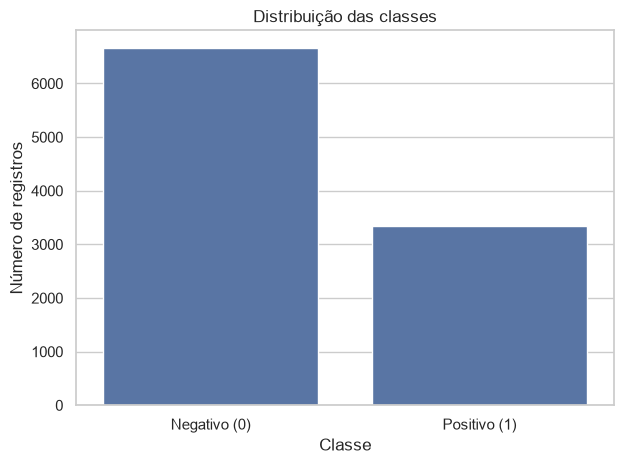

In [25]:
ax = sns.barplot(x=balance.index, y=balance["quantidade"], color="#4c72b0")
ax.set(title="Distribuição das classes", xlabel="Classe", ylabel="Número de registros")

plt.tight_layout()
plt.show()

## Distribuição das variáveis

Os gráficos são descritivos: diferenças entre grupos e correlações não demonstram causalidade.

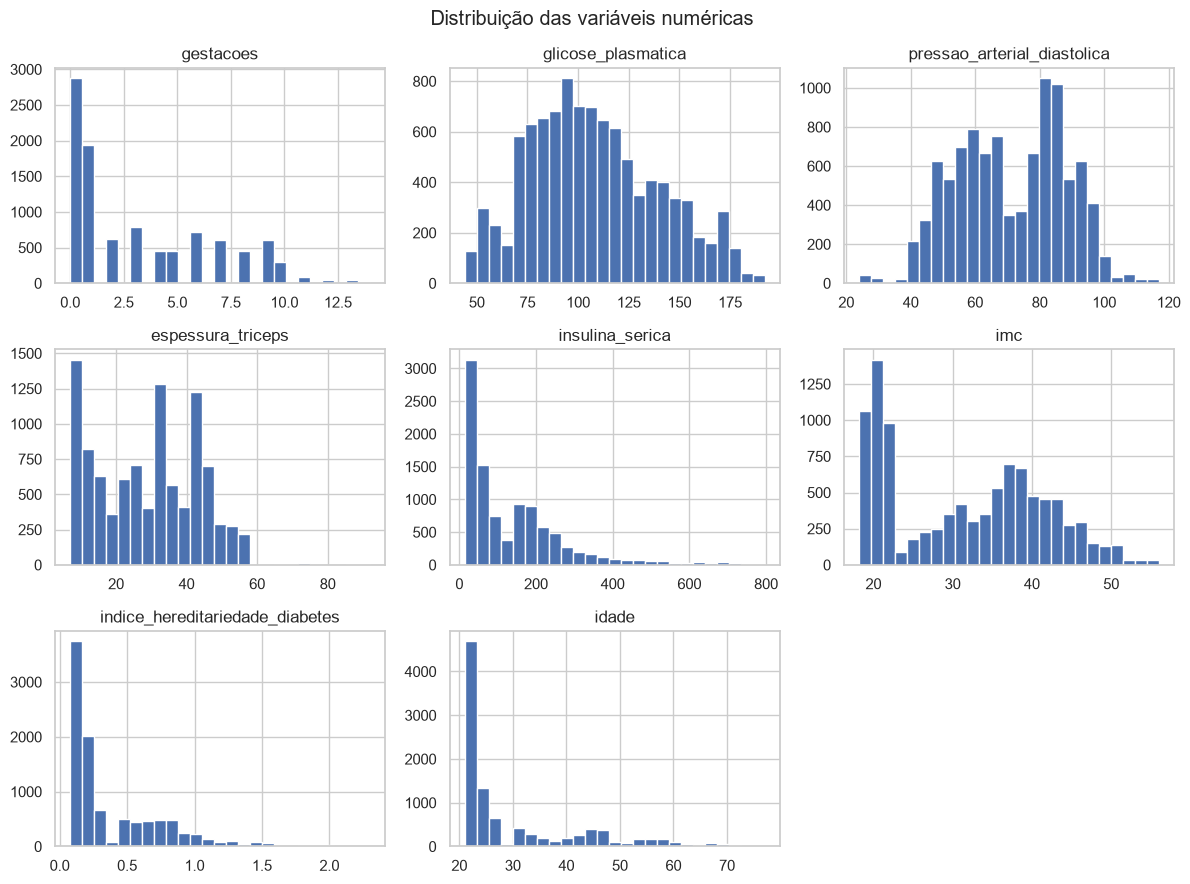

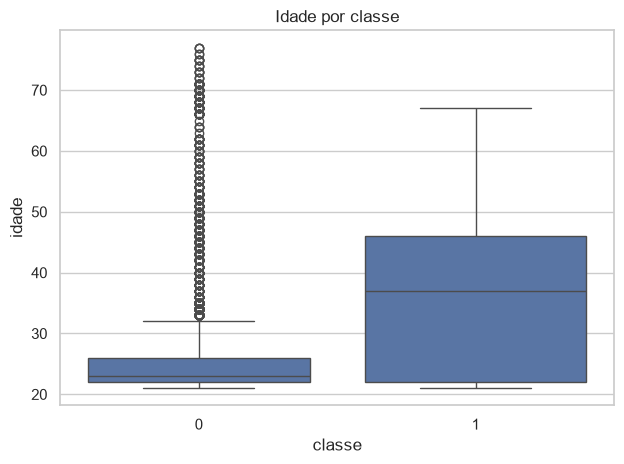

In [ ]:
numeric_columns = [
    name
    for name in data.select_dtypes(include="number").columns
    if name not in {TARGET, "id_paciente"}
]

if numeric_columns:
    data[numeric_columns].hist(
        bins=25,
        figsize=(12, max(3, 3 * ((len(numeric_columns) + 2) // 3))),
        layout=((len(numeric_columns) + 2) // 3, 3),
    )
    plt.suptitle("Distribuição das variáveis numéricas")
    plt.tight_layout()
    plt.show()

if "idade" in data:
    sns.boxplot(data=data, x=TARGET, y="idade")
    plt.title("Idade por classe")
    plt.tight_layout()
    plt.show()

### Zeros e correlações

Verificamos a frequência de zeros nas medidas abaixo, sem convertê-los automaticamente em valores ausentes. A interpretação exige conferir o significado de cada campo na fonte. `id_paciente` é excluído da matriz de correlação.

In [ ]:
measurement_columns = [
    "glicose_plasmatica",
    "pressao_arterial_diastolica",
    "espessura_triceps",
    "insulina_serica",
    "imc",
]

zeros = data[measurement_columns].eq(0).sum()

display(
    pd.DataFrame({"zeros": zeros, "percentual": zeros.div(len(data)).mul(100).round(2)})
)

,zeros,percentual
glicose_plasmatica,0,0.0
pressao_arterial_diastolica,0,0.0
espessura_triceps,0,0.0
insulina_serica,0,0.0
imc,0,0.0


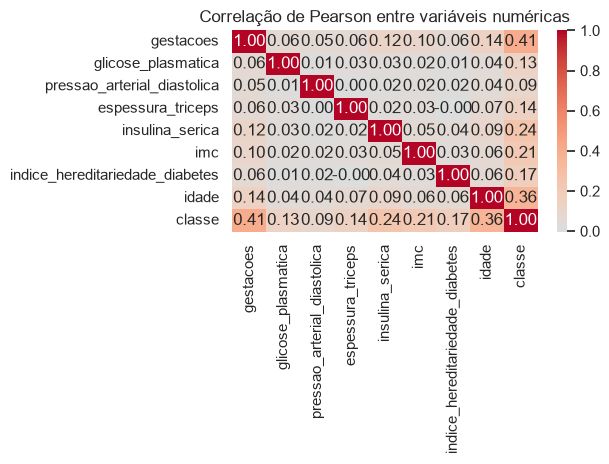

In [ ]:
correlation_columns = numeric_columns + [TARGET]

sns.heatmap(
    data[correlation_columns].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f"
)

plt.title("Correlação de Pearson entre variáveis numéricas")
plt.tight_layout()
plt.show()